# 01 · Análisis exploratorio de datos (EDA)

**Proyecto:** priorización de cartera de cobranzas. El modelo predice qué créditos **pagan en los próximos 7 días**, para ordenar la gestión diaria de los cobradores.

**Datos:** la OBT del PSet 2 (`CARTERA.GOLD.OBT_CARTERA_DIARIA` en Snowflake), con una fila por **crédito y fecha de corte** (octubre 2026). Los datos son anonimizados y sintéticos.

Este notebook **no modifica los datos**: los explora para tomar decisiones de modelado. Cada hallazgo se documenta con su evidencia y su consecuencia en el modelo.

## 1. Carga de la OBT

La lectura desde Snowflake vive en `src/datos.py` y se importa aquí, en lugar de copiar el código. Las credenciales se leen del archivo `.env`, que no se sube al repositorio.

In [1]:
import sys
sys.path.append("..")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from src.datos import cargar_obt

obt = cargar_obt()
print(obt.shape)
obt.head()

(261255, 37)


,fecha_corte,numero_operacion,cartera_diaria_id,cliente_id,estado_operacion,dias_mora,rango_mora,cuotas_por_pagar,cuotas_pagadas,cuotas_mora,...,fecha_primera_cuota,tipo_garantia,es_cancelada,tiene_cartera,anio,mes,dia,dia_semana,es_fin_de_semana,es_fin_de_mes
0,2026-10-07,OP_009496,3851687518871658698,CLI_003145,ACTIVO,0,0,55,17,0,...,2025-06-02,PAGARE,False,True,2026,10,7,3,False,False
1,2026-10-08,OP_009496,1627886982822710885,CLI_003145,ACTIVO,0,0,55,17,0,...,2025-06-02,PAGARE,False,True,2026,10,8,4,False,False
2,2026-10-09,OP_009496,2529057854962755803,CLI_003145,ACTIVO,0,0,55,17,0,...,2025-06-02,PAGARE,False,True,2026,10,9,5,False,False
3,2026-10-10,OP_009496,-8244980550060481739,CLI_003145,ACTIVO,0,0,55,17,0,...,2025-06-02,PAGARE,False,True,2026,10,10,6,True,False
4,2026-10-11,OP_009496,1105340478929085154,CLI_003145,ACTIVO,0,0,55,17,0,...,2025-06-02,PAGARE,False,True,2026,10,11,7,True,False


## 2. Tamaño, tipos de datos y valores faltantes

Para cada columna se muestra su tipo de dato, cuántos valores faltan y qué porcentaje representan. Sirve para decidir qué columnas necesitan imputación, cuáles hay que convertir de tipo y cuáles no aportan información.

In [2]:
resumen = pd.DataFrame({
    "tipo": obt.dtypes,
    "faltantes": obt.isna().sum(),
    "pct_faltantes": (obt.isna().mean() * 100).round(2),
})
resumen

,tipo,faltantes,pct_faltantes
fecha_corte,object,0,0.00
numero_operacion,object,0,0.00
cartera_diaria_id,int64,0,0.00
cliente_id,object,0,0.00
estado_operacion,object,0,0.00
dias_mora,int16,0,0.00
rango_mora,object,0,0.00
cuotas_por_pagar,int16,0,0.00
cuotas_pagadas,int8,0,0.00
cuotas_mora,int8,0,0.00


**Hallazgos de la estructura:**

1. **Fechas guardadas como texto.** `fecha_corte`, `fecha_proxima_cuota`, `fecha_primera_cuota_mora`, `fecha_efectiva` y `fecha_primera_cuota` son de tipo `object`.
   - **Consecuencia:** se convierten a fecha antes de usarlas. Son necesarias para construir el target (pagos de los 7 días siguientes) y para la separación temporal.

2. **Faltantes concentrados en dos fechas.** `fecha_primera_cuota_mora` tiene 63.95% de faltantes y `fecha_proxima_cuota` 3.65%. `dia_pago` tiene apenas 31 (0.01%). El resto de columnas está completo.
   - **Consecuencia:** antes de imputar, se revisa en la sección 3 si los faltantes son *estructurales* (por ejemplo, un crédito al día no tiene "primera cuota en mora").

3. **Columnas que no son features.** `cartera_diaria_id`, `numero_operacion` y `cliente_id` son identificadores, y `anio`/`mes` son constantes (todo es octubre 2026).
   - **Consecuencia:** se excluyen del modelo. `numero_operacion` se conserva solo para construir el target.

4. **Posible fuga de datos.** `es_cancelada` y `tiene_cartera` vienen de la dimensión de operaciones y describen el estado **actual** del crédito, no el de cada fecha de corte.    `num_pagos_dia` y `monto_pagado_dia` se agregan por **fecha valor** del pago (cuando el dinero ingresa a las cuentas), no por la fecha en que se aplica en el sistema: se revisa en la sección 10 si se conocen al momento de predecir.
   - **Consecuencia:** no se usan tal cual. Se evalúan en el notebook de features (usar el valor del día anterior o excluirlas).

## 3. Conversión de fechas y faltantes estructurales

Se convierten las columnas de fecha a tipo fecha. Luego se comprueba si los faltantes de `fecha_primera_cuota_mora` corresponden exactamente a los créditos sin mora (`dias_mora = 0`). Si es así, el faltante no es un error: significa "no está en mora".

In [3]:
fechas = ["fecha_corte", "fecha_proxima_cuota", "fecha_primera_cuota_mora",
          "fecha_efectiva", "fecha_primera_cuota"]
for c in fechas:
    obt[c] = pd.to_datetime(obt[c])

pd.crosstab(obt["fecha_primera_cuota_mora"].isna(), obt["dias_mora"] > 0,
            rownames=["fecha_mora_vacia"], colnames=["en_mora"])

en_mora,False,True
fecha_mora_vacia,,
False,0,94180
True,167075,0


**Hallazgo: los faltantes de `fecha_primera_cuota_mora` son estructurales.**
- **Evidencia:** las 167,075 filas con fecha vacía tienen `dias_mora = 0`, y las 94,180 con fecha llena tienen `dias_mora > 0`. No hay ningún caso cruzado.
- **Consecuencia en el modelo:** no se imputa (rellenar una fecha inventada sería un error). La información ya está en `dias_mora`. Además, el 36% de las filas está en mora (94,180 de 261,255), un dato clave para entender el target.

**Verificación:** si `fecha_primera_cuota_mora` es la cuota impaga más antigua a la fecha del corte, entonces `dias_mora` debe ser igual a los días entre esa fecha y `fecha_corte`.

In [4]:
en_mora = obt[obt["dias_mora"] > 0]
diferencia = (en_mora["fecha_corte"] - en_mora["fecha_primera_cuota_mora"]).dt.days
print("Filas en mora:", len(en_mora))
print("% donde dias_mora = fecha_corte - fecha_primera_cuota_mora:",
      round((diferencia == en_mora["dias_mora"]).mean() * 100, 2))

Filas en mora: 94180
% donde dias_mora = fecha_corte - fecha_primera_cuota_mora: 100.0


**Hallazgo: `fecha_primera_cuota_mora` es redundante con `dias_mora`.**
- **Evidencia:** en el 100% de las filas en mora, `dias_mora` es exactamente igual a `fecha_corte − fecha_primera_cuota_mora`. El campo es la cuota impaga más antigua a la fecha del corte (se vacía cuando el cliente se pone al día), no la primera mora histórica del cliente.
- **Consecuencia en el modelo:** se excluye de las features, porque no aporta información adicional a `dias_mora`.

**Verificación:** ¿los faltantes de `fecha_proxima_cuota` y de `dia_pago` corresponden a créditos que ya no tienen cuotas por pagar?

In [5]:
pd.crosstab([obt["fecha_proxima_cuota"].isna(), obt["dia_pago"].isna()],
            obt["cuotas_por_pagar"] == 0,
            rownames=["proxima_cuota_vacia", "dia_pago_vacio"],
            colnames=["sin_cuotas_por_pagar"])

sin_cuotas_por_pagar                 False  True 
proxima_cuota_vacia dia_pago_vacio               
False               False           251728      0
True                False             9496      0
                    True                 0     31

**Verificación:** los créditos sin próxima cuota pero con cuotas pendientes, ¿tienen todas sus cuotas pendientes ya vencidas (plazo terminado)?

In [6]:
sin_proxima = obt[obt["fecha_proxima_cuota"].isna() & (obt["cuotas_por_pagar"] > 0)]
print("Filas:", len(sin_proxima))
print("% con cuotas_por_pagar = cuotas_mora:",
      round((sin_proxima["cuotas_por_pagar"] == sin_proxima["cuotas_mora"]).mean() * 100, 2))
sin_proxima["estado_operacion"].value_counts()

Filas: 9496
% con cuotas_por_pagar = cuotas_mora: 100.0


estado_operacion
NON ACCRUAL    7088
CASTIGADA      2046
VENCIDO         362
Name: count, dtype: int64

**Hallazgo: los faltantes de `dia_pago` y `fecha_proxima_cuota` son estructurales.**
- **Evidencia:**
  - Los 31 vacíos de `dia_pago` son un solo crédito (`OP_015755`) ya pagado por completo: capital, deuda, cuotas y días de mora en 0, aunque sigue con estado ACTIVO. Sin cuotas, no hay día de pago.
  - De los 9,527 vacíos de `fecha_proxima_cuota`, 31 son ese mismo crédito; en los otros 9,496, el 100% tiene `cuotas_por_pagar = cuotas_mora`. Es decir, su **plazo terminó** y todas sus cuotas pendientes ya vencieron. Sus estados son NON ACCRUAL, CASTIGADA y VENCIDO.
- **Consecuencia en el modelo:**
  - No se imputan fechas inventadas. `fecha_proxima_cuota` no se usa directamente; de ella se puede derivar una feature "plazo terminado" (`cuotas_por_pagar = cuotas_mora`), que identifica créditos muy deteriorados.
  - `dia_pago` no tiene vacíos en la población del modelo, porque ese crédito no está en mora y sale con el filtro de la sección 6. Igual se deja un imputador (moda) en el Pipeline como protección, por si en producción llega un crédito con este campo vacío.
  - Los créditos castigados, non accrual y vencidos **se mantienen** en la población del modelo, porque el call center también los gestiona.

## 4. Estadística descriptiva

Resumen de las variables numéricas: promedio, desviación estándar, mínimo, cuartiles y máximo. Se excluyen el identificador `cartera_diaria_id` y las constantes `anio` y `mes`. Sirve para detectar escalas muy distintas entre variables y posibles valores atípicos.

In [7]:
numericas = obt.select_dtypes("number").drop(columns=["cartera_diaria_id", "anio", "mes"])
numericas.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
dias_mora,261255.0,100.26,286.99,0.00,0.00,0.00,15.00,2141.00
cuotas_por_pagar,261255.0,45.43,17.63,0.00,34.00,48.00,59.00,156.00
cuotas_pagadas,261255.0,19.33,14.95,0.00,7.00,16.00,29.00,72.00
cuotas_mora,261255.0,3.14,8.39,0.00,0.00,0.00,1.00,60.00
dia_pago,261224.0,13.17,7.77,1.00,2.00,16.00,16.00,31.00
capital_insoluto,261255.0,15884.99,13708.05,0.00,11207.86,14874.32,19128.20,822904.68
capital_vencido,261255.0,884.50,2979.93,0.00,0.00,0.00,283.78,105861.74
saldo_cuota_mas_vencida,261255.0,271.42,676.86,0.00,0.00,0.00,416.13,57114.06
valor_deuda_exigible,261255.0,1690.01,5375.95,0.00,0.00,0.00,554.74,147194.69
valor_cuota_exigible_vigente,261255.0,706.41,7010.18,0.00,376.08,484.49,616.16,344138.00


**Hallazgos de la estadística descriptiva:**

1. **`dias_mora` muy sesgada a la derecha.** La mediana es 0 (más de la mitad de las filas está al día), el 75% tiene 15 días o menos, pero el promedio es 100 y el máximo 2,141 días (casi 6 años).
   - **Consecuencia:** el promedio no representa a la cartera. Se usa la correlación de **Spearman** (basada en rangos, robusta a colas largas) y se prueban **tramos de mora** como feature.

2. **Variables de dinero con colas largas y escalas muy distintas.** `capital_insoluto` tiene mediana de 14,874 y máximo de 822,905; `valor_cuota_exigible_vigente` tiene mediana de 484 y máximo de 344,138.
   - **Consecuencia:** se revisan atípicos (IQR y Z-score) y se **escalan** las variables dentro del Pipeline. Para los modelos lineales y la red neuronal se prueba **log(1 + x)**.

3. **Pagos y gestiones son eventos poco frecuentes por día.** `num_pagos_dia` tiene promedio 0.05: hay un pago en ~5% de los créditos-día. Las gestiones también (0.05), con contacto efectivo en 3% y compromiso de pago en 2%.
   - **Consecuencia:** el target "paga en 7 días" acumula una semana, así que será más frecuente que 5%, pero puede estar **desbalanceado** (sección 5). Las gestiones (el tratamiento del uplift) también son escasas.

4. **`dia_pago` concentrado en dos fechas.** El 25% está en el día 2, y la mediana y el 75% en el día 16.
   - **Consecuencia:** es más una categoría que un número continuo. Se trata como **categórica** (one-hot) o se usa la distancia al día de pago.

5. **Valores sospechosos.** `tasa_nominal` tiene mínimo 0, y `monto_financiado` mínimo 92 (muy bajo para un crédito de auto).
   - **Consecuencia:** se revisan en la detección de atípicos.

## 5. Distribución del target y desbalance de clases

**Target:** `paga_7d` = 1 si en los 7 días siguientes al corte el crédito **sube sus cuotas pagadas** (pagó una cuota completa) **o baja sus días de mora** (cubrió la cuota más vencida). Un abono parcial que no cubre una cuota no cuenta como pago.

Se usan variables de estado del sistema de cartera, y no los montos, porque los montos sintéticos tienen ruido de ±10%. Se excluyen los cortes del 25 al 31 de octubre, porque sus 7 días siguientes no se observan completos. El target se construye con `agregar_target()` de `src/datos.py`, que se reutiliza en el notebook de features.

Filas con target: 201935
paga_7d
0    167281
1     34654
Name: count, dtype: int64
% que paga en 7 días: 17.16
          count      mean
en_mora                  
False    129957  0.163231
True      71978  0.186738


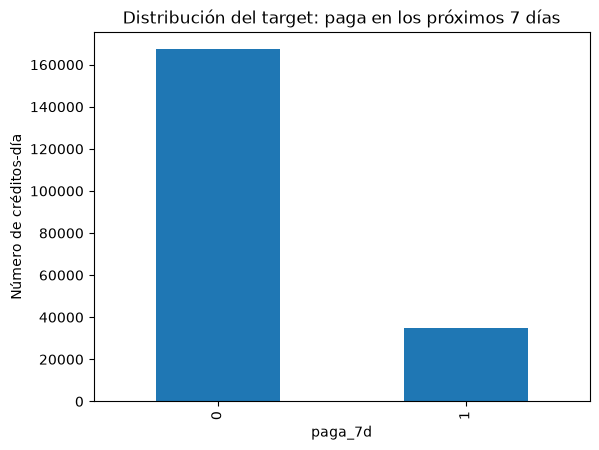

In [8]:
from src.datos import agregar_target

obt = agregar_target(obt)
print("Filas con target:", obt.shape[0])
print(obt["paga_7d"].value_counts())
print("% que paga en 7 días:", round(obt["paga_7d"].mean() * 100, 2))

obt["en_mora"] = obt["dias_mora"] > 0
print(obt.groupby("en_mora")["paga_7d"].agg(["count", "mean"]))

obt["paga_7d"].value_counts().sort_index().plot(kind="bar")
plt.title("Distribución del target: paga en los próximos 7 días")
plt.xlabel("paga_7d")
plt.ylabel("Número de créditos-día")
plt.savefig("../docs/figuras/eda_target.png", bbox_inches="tight")
plt.show()

**Hallazgo: target desbalanceado.**
- **Evidencia:** solo el 17.16% de los créditos-día paga en los 7 días siguientes (34,654 de 201,935). En la población del modelo (créditos en mora) la proporción es 18.7% (71,978 filas): aproximadamente **1 positivo por cada 4 negativos**.
- **Consecuencia en el modelo:**
  - La **accuracy** no sirve como métrica técnica: un modelo que siempre dice "no paga" acertaría el 81% sin aprender nada. Se usa **PR-AUC** (área bajo la curva precisión-recall), que se enfoca en la clase minoritaria.
  - Se prueba `class_weight="balanced"` en los modelos que lo permiten.
  - El **umbral de decisión** no será 0.5: se elige en la selección según el costo de cada error.
  - La validación cruzada sigue siendo **temporal** (no estratificada), pero se verifica que cada pliegue tenga positivos suficientes.

**Verificación:** ¿se gestiona a los clientes al día? Si casi no reciben gestiones, no forman parte de la decisión que el modelo apoya.

In [9]:
obt.groupby("en_mora")[["num_gestiones_dia", "contacto_efectivo_dia"]].mean().round(4)

,num_gestiones_dia,contacto_efectivo_dia
en_mora,,
False,0.0039,0.0035
True,0.1296,0.0811


**Hallazgo: la gestión de cobranza se concentra en créditos en mora.**
- **Evidencia:** los créditos en mora reciben 0.1296 gestiones por día, frente a 0.0039 de los créditos al día (33 veces más). El contacto efectivo sigue el mismo patrón (0.0811 vs. 0.0035).
- **Consecuencia en el modelo:** la población del modelo son solo los créditos en mora, que es donde ocurre la decisión de a quién llamar. Incluir los créditos al día no cambiaría ninguna decisión y no permitiría estimar el efecto incremental, porque casi no hay créditos al día gestionados para comparar. Un modelo preventivo para clientes al día (alerta temprana de entrada en mora) queda como trabajo futuro.

## 6. Población del modelo: créditos en mora

Los cobradores solo gestionan créditos en mora, así que el modelo se entrena y evalúa únicamente con cortes donde `dias_mora > 0`.

El filtro se aplica **después** de construir el target. Ejemplo: si un cliente que debía una sola cuota la paga, ese día queda con `dias_mora = 0`. Si se filtrara antes, ese día de pago desaparecería y los cortes anteriores quedarían marcados, por error, como "no paga".

In [10]:
obt = obt[obt["en_mora"]].reset_index(drop=True)
print("Filas en la población del modelo:", obt.shape[0])
print("% que paga en 7 días:", round(obt["paga_7d"].mean() * 100, 2))
print("Vacíos de dia_pago en la población:", obt["dia_pago"].isna().sum())

Filas en la población del modelo: 71978
% que paga en 7 días: 18.67
Vacíos de dia_pago en la población: 0


**Hallazgos de la población del modelo:**

1. **La población se reduce a un tercio, pero sigue siendo suficiente.**
   - **Evidencia:** de 201,935 créditos-día con target quedan 71,978 en mora (36%), del 1 al 24 de octubre. Son en promedio unos 3,000 créditos en mora por día de corte (71,978 / 24).
   - **Consecuencia en el modelo:** el volumen alcanza para entrenar y validar con varios pliegues temporales. Los ~3,000 créditos diarios son el tamaño de la lista que el modelo debe ordenar cada mañana.

2. **La proporción de pago en mora (18.67%) es la referencia del azar.**
   - **Evidencia:** si un cobrador eligiera a quién llamar al azar, aproximadamente 1 de cada 5 créditos llamados pagaría al menos una cuota en los 7 días siguientes.
   - **Consecuencia en el modelo:** es el piso que cualquier modelo debe superar. La métrica de negocio compara cuántos pagos captura el modelo en el top de la lista frente a este 18.67%.

## 7. Valores atípicos: IQR y Z-score

Se mide qué porcentaje de filas es atípico en las variables numéricas principales, con dos métodos:
- **IQR:** valores por debajo de Q1 − 1.5·IQR o por encima de Q3 + 1.5·IQR (los puntos fuera del diagrama de caja).
- **Z-score:** valores a 3 o más desviaciones estándar del promedio.

El análisis se hace sobre la población del modelo (créditos en mora). Un atípico es un **candidato a revisar**, no a eliminar: puede ser un error, un caso raro pero real, o una regla del negocio.

In [11]:
from scipy import stats

variables = ["dias_mora", "cuotas_mora", "capital_insoluto", "capital_vencido",
             "saldo_cuota_mas_vencida", "valor_deuda_exigible",
             "valor_cuota_exigible_vigente", "monto_financiado", "tasa_nominal"]

filas = []
for v in variables:
    x = obt[v]
    q1 = x.quantile(0.25)
    q3 = x.quantile(0.75)
    iqr = q3 - q1
    pct_iqr = ((x < q1 - 1.5 * iqr) | (x > q3 + 1.5 * iqr)).mean() * 100
    pct_z = (np.abs(stats.zscore(x)) >= 3).mean() * 100
    filas.append({"variable": v,
                  "% atipicos IQR": round(pct_iqr, 2),
                  "% atipicos Z>=3": round(pct_z, 2)})

pd.DataFrame(filas)

,variable,% atipicos IQR,% atipicos Z>=3
0,dias_mora,9.07,1.94
1,cuotas_mora,7.96,1.76
2,capital_insoluto,2.17,0.31
3,capital_vencido,12.09,1.36
4,saldo_cuota_mas_vencida,10.32,1.84
5,valor_deuda_exigible,11.42,1.68
6,valor_cuota_exigible_vigente,3.23,0.32
7,monto_financiado,5.73,0.49
8,tasa_nominal,1.71,0.80


**Hallazgo: las variables de mora y deuda tienen una cola larga de atípicos legítimos.**
- **Evidencia:** con IQR, entre 8% y 12% de las filas son atípicas en `dias_mora`, `cuotas_mora`, `capital_vencido`, `saldo_cuota_mas_vencida` y `valor_deuda_exigible`; con Z-score, menos del 2%. El Z-score subestima los atípicos porque los valores extremos inflan la desviación estándar. Estos atípicos corresponden a créditos con mora muy alta (castigados, non accrual, vencidos), que son casos reales gestionados por el call center.
- **Consecuencia en el modelo:**
  - **No se eliminan:** el modelo va a encontrar estos créditos en producción.
  - Para la regresión logística y la red neuronal, que son sensibles a la escala y a los extremos, se aplica **log(1 + x)** a las variables de dinero y mora antes de escalar, dentro del Pipeline.
  - Los modelos de árboles (Random Forest, boosting) no lo necesitan, porque dividen por rangos y no les afecta la magnitud de los extremos.

## 8. Diagramas de caja

Visualización de los atípicos detectados con IQR: la caja va de Q1 a Q3, la línea central es la mediana y los puntos sueltos son los valores fuera de 1.5·IQR. Se usa escala logarítmica en el eje vertical para que la cola larga no aplaste la caja.

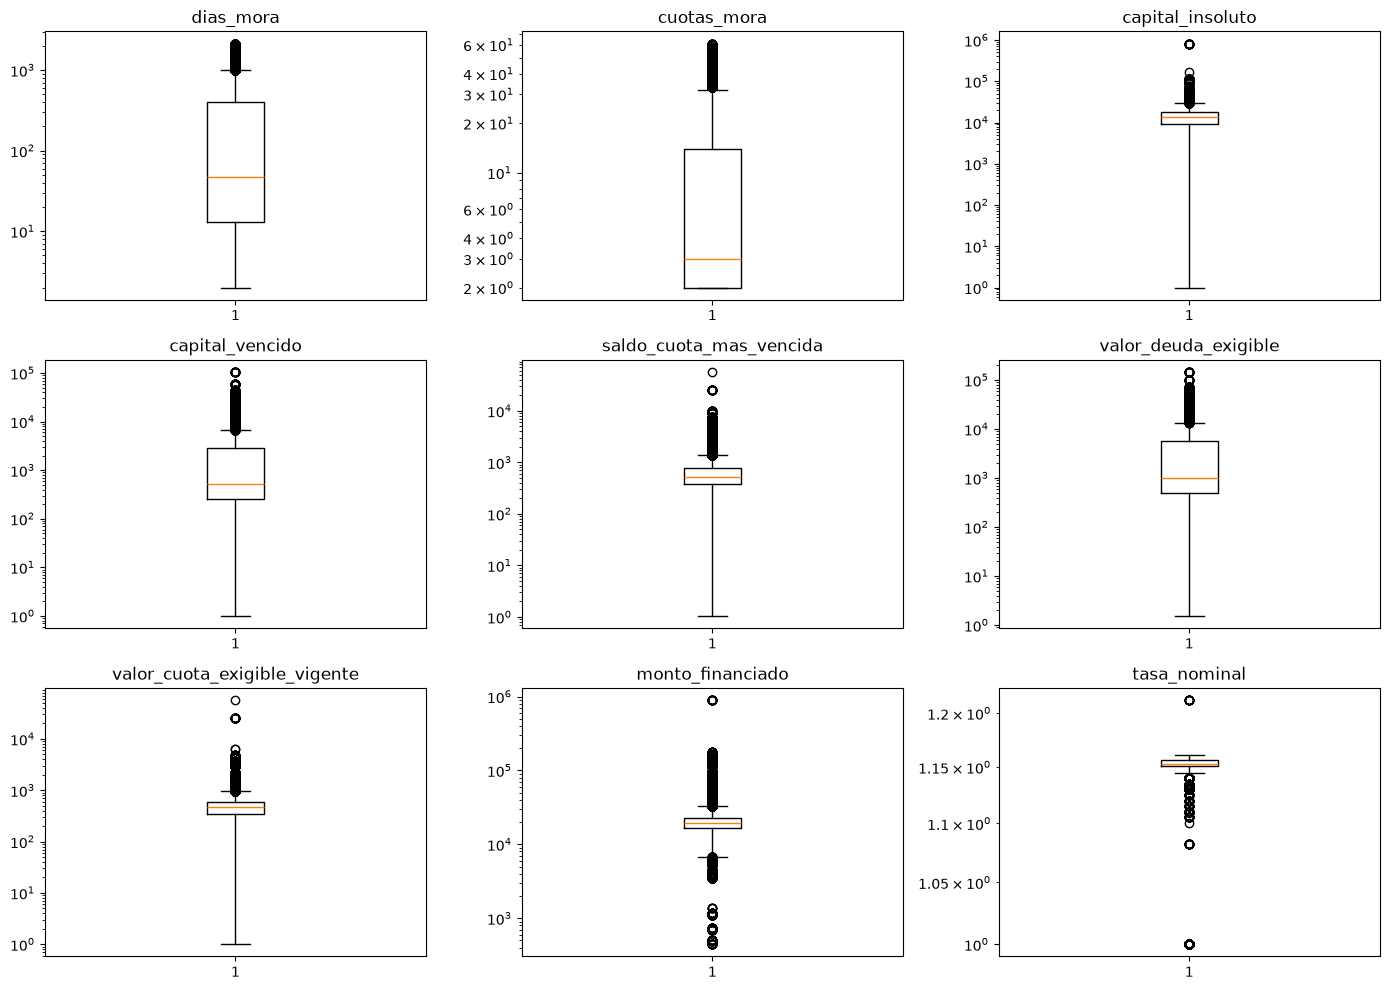

In [12]:
fig, ejes = plt.subplots(3, 3, figsize=(14, 10))
for v, eje in zip(variables, ejes.flatten()):
    eje.boxplot(obt[v] + 1)
    eje.set_yscale("log")
    eje.set_title(v)
plt.tight_layout()
plt.savefig("../docs/figuras/eda_boxplots.png", bbox_inches="tight")
plt.show()

**Hallazgo: los diagramas de caja confirman la cola larga y muestran valores aislados.**
- **Evidencia:** en las variables de mora y deuda, los atípicos forman una cola continua (muchos créditos con mora alta), coherente con la tabla anterior. En cambio, `capital_insoluto` y `monto_financiado` tienen puntos aislados cerca de 800,000–900,000; `monto_financiado` tiene valores menores a 1,000, y `tasa_nominal` tiene valores en 0.
- **Consecuencia en el modelo:** la cola continua se conserva (ver hallazgo anterior). Los valores aislados se inspeccionan en la siguiente sección para decidir si son errores.

## 9. Inspección de valores sospechosos

Se cuentan las filas y los créditos con valores que no tienen sentido de negocio para un crédito de auto: tasa nominal de 0, monto financiado menor a 1,000 y capital insoluto mayor a 500,000. Luego se muestra el detalle de los créditos con capital extremo.

In [13]:
sospechosos = {
    "tasa_nominal = 0": obt["tasa_nominal"] == 0,
    "monto_financiado < 1,000": obt["monto_financiado"] < 1000,
    "capital_insoluto > 500,000": obt["capital_insoluto"] > 500000,
}
for nombre, filtro in sospechosos.items():
    print(nombre, "| filas:", filtro.sum(),
          "| créditos:", obt.loc[filtro, "numero_operacion"].nunique())

obt.loc[obt["capital_insoluto"] > 500000,
        ["numero_operacion", "monto_financiado", "capital_insoluto",
         "valor_cuota_exigible_vigente", "total_cuotas", "tasa_nominal",
         "estado_operacion"]].drop_duplicates("numero_operacion")

tasa_nominal = 0 | filas: 408 | créditos: 19
monto_financiado < 1,000 | filas: 120 | créditos: 5
capital_insoluto > 500,000 | filas: 24 | créditos: 1


,numero_operacion,monto_financiado,capital_insoluto,valor_cuota_exigible_vigente,total_cuotas,tasa_nominal,estado_operacion
22432,OP_005683,892434.77,822904.68,25141.94,52.0,0.156,NON ACCRUAL


**Verificación:** ¿en qué estado están los créditos con tasa nominal 0?

In [14]:
obt.loc[obt["tasa_nominal"] == 0, "estado_operacion"].value_counts()

estado_operacion
NON ACCRUAL    293
VENCIDO         91
CASTIGADA       24
Name: count, dtype: int64

**Hallazgo: los valores sospechosos son pocos créditos, con dos explicaciones distintas.**
- **Evidencia:**
  - **Tasa nominal 0** (19 créditos, 408 filas): no es un error. Son créditos **reestructurados o especiales**, según la operación del área de cobranzas, y el 100% está en un estado deteriorado (293 filas NON ACCRUAL, 91 VENCIDO, 24 CASTIGADA).
  - **Capital > 500,000** (1 crédito, `OP_005683`) y **monto financiado < 1,000** (5 créditos): sus montos son coherentes entre sí, pero no son realistas para un crédito de auto. Son un **artefacto de la generación de montos sintéticos** del PSet 2 (factor por operación de una mezcla gaussiana).
- **Consecuencia en el modelo:**
  - Ningún crédito se elimina: son 25 créditos de ~3,000 diarios, su efecto en los modelos de árboles es mínimo, y **log(1 + x)** reduce su peso en los modelos lineales y la red neuronal.
  - La tasa 0 es información útil, pero puede **repetir** lo que ya dice `estado_operacion`, porque todos esos créditos están deteriorados. En el notebook de features se comprueba si `es_tasa_cero` aporta algo más que el estado del crédito.
  - Los montos extremos se documentan como **limitación de los datos sintéticos**.

## 10. Relación entre el target y las variables: correlación de Spearman

Se mide la correlación de cada variable numérica con el target `paga_7d`. Se usa **Spearman** y no Pearson por dos razones:
1. Las variables de mora y dinero tienen **colas largas** (sección 4 y 7). Pearson usa los valores originales y se deja arrastrar por los extremos; Spearman usa el **orden** (rangos), así que un crédito con 2,000 días de mora no pesa más que uno con 500.
2. Spearman detecta relaciones **monótonas** (si una sube, la otra tiende a subir o bajar), aunque no sean líneas rectas.

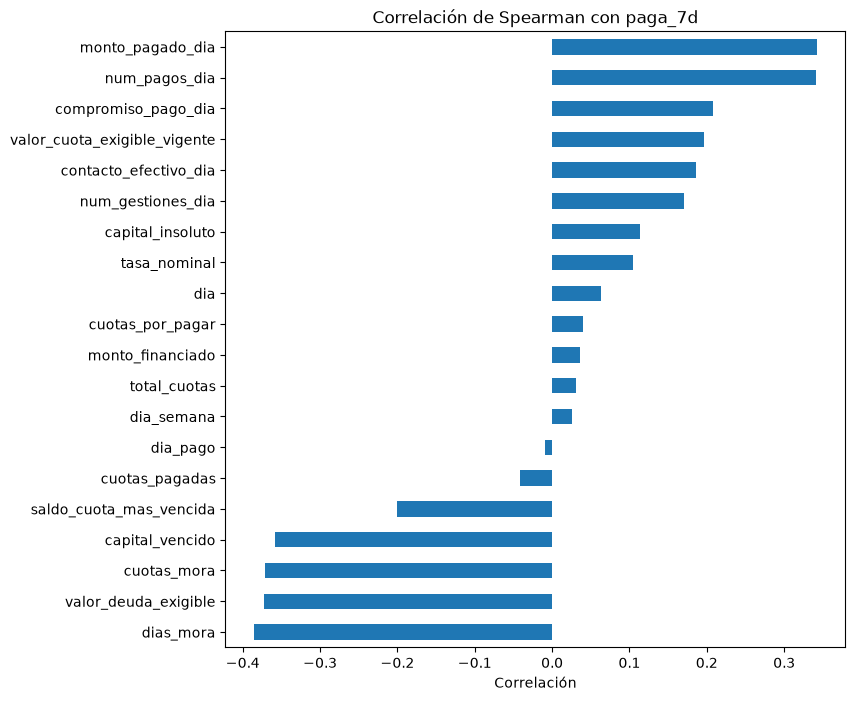

dias_mora                      -0.386
valor_deuda_exigible           -0.373
cuotas_mora                    -0.371
capital_vencido                -0.358
saldo_cuota_mas_vencida        -0.201
cuotas_pagadas                 -0.041
dia_pago                       -0.009
dia_semana                      0.025
total_cuotas                    0.030
monto_financiado                0.036
cuotas_por_pagar                0.040
dia                             0.064
tasa_nominal                    0.105
capital_insoluto                0.113
num_gestiones_dia               0.170
contacto_efectivo_dia           0.185
valor_cuota_exigible_vigente    0.197
compromiso_pago_dia             0.209
num_pagos_dia                   0.341
monto_pagado_dia                0.343
dtype: float64

In [15]:
numericas = obt.select_dtypes("number").drop(columns=["cartera_diaria_id", "anio", "mes", "paga_7d"])
correlaciones = numericas.corrwith(obt["paga_7d"], method="spearman").sort_values()

correlaciones.plot(kind="barh", figsize=(8, 8))
plt.title("Correlación de Spearman con paga_7d")
plt.xlabel("Correlación")
plt.savefig("../docs/figuras/eda_correlacion_target.png", bbox_inches="tight")
plt.show()

correlaciones.round(3)

**Hallazgos de la relación con el target:**

1. **La profundidad de la mora es la señal negativa más fuerte.** `dias_mora` (−0.386), `valor_deuda_exigible` (−0.373), `cuotas_mora` (−0.371) y `capital_vencido` (−0.358): mientras más deteriorado el crédito, menor la probabilidad de pagar en 7 días.
   - **Consecuencia:** `dias_mora` es la variable más importante. Como las cuatro miden casi lo mismo, se revisa su correlación entre sí (sección 11) para evitar redundancia en los modelos lineales.

2. **Los pagos del día tienen la correlación positiva más alta, pero contienen parte del target.** `monto_pagado_dia` (0.343) y `num_pagos_dia` (0.341).
   - **Evidencia del negocio:** en la OBT, los pagos se ubican por **fecha valor**. Las transferencias interbancarias, los comprobantes enviados tarde o los pagos fuera de horario se **aplican días después**. Un pago con fecha valor del día *d* puede no verse en la mañana de *d+1*, cuando se arma la lista, y la cuota pagada aparece en un cierre posterior, dentro de la ventana del target.
   - **Consecuencia:** no se usan estas columnas de la OBT (**fuga del objetivo**). Tampoco se construye una feature de pagos recientes: los datos no registran cuándo cada pago se vuelve visible para el cobrador (por ejemplo, en el módulo de pagos pendientes), así que no se puede garantizar que existiera al armar la lista.

3. **La gestión se asocia positivamente con el pago.** `compromiso_pago_dia` (0.209), `contacto_efectivo_dia` (0.185) y `num_gestiones_dia` (0.170).
   - **Consecuencia:** apoya el enfoque de efecto incremental (S-learner) con la gestión como tratamiento. Es una asociación, no una prueba causal: los cobradores no eligen al azar a quién llamar (sesgo de selección).

4. **`dia_pago` como número casi no se relaciona con el target** (−0.009).
   - **Consecuencia:** refuerza el hallazgo de la sección 4: se trata como **categórica** o como distancia al día de pago, no como número continuo.

## 11. Mapa de calor de correlaciones entre variables

Correlación de Spearman entre las variables principales y el target. Sirve para detectar variables **redundantes** (que miden casi lo mismo), que pueden confundir a los modelos lineales.

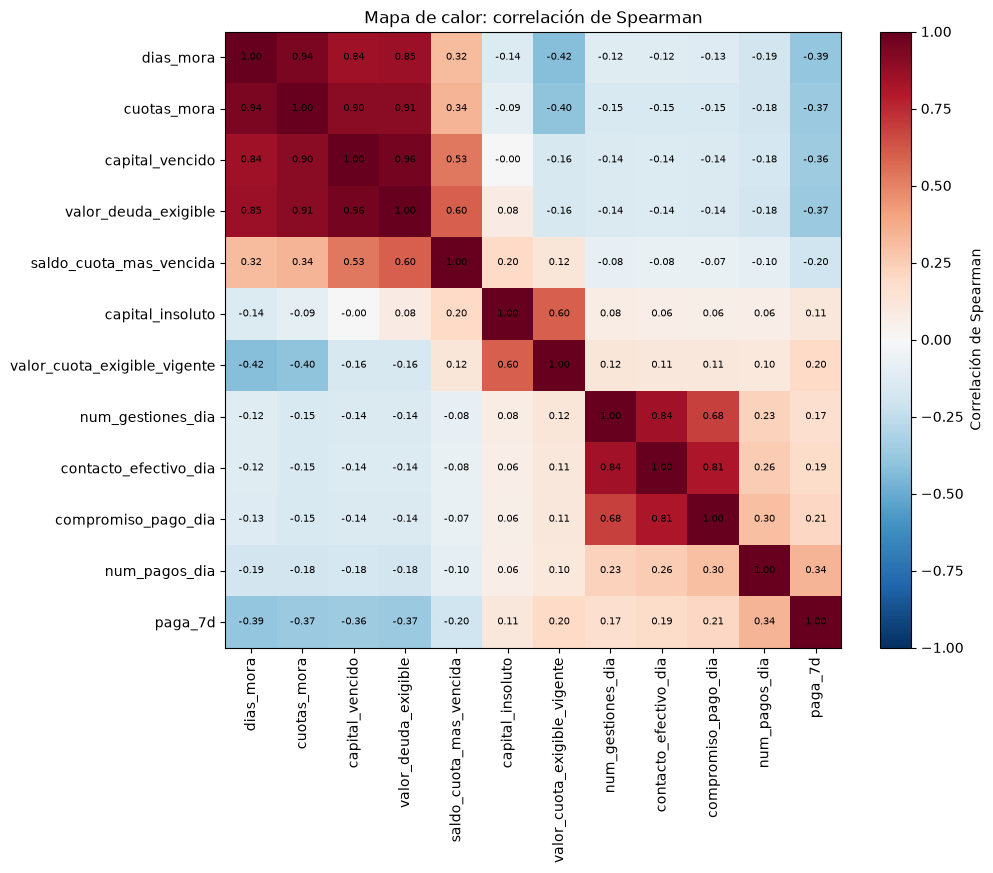

In [16]:
principales = ["dias_mora", "cuotas_mora", "capital_vencido", "valor_deuda_exigible",
               "saldo_cuota_mas_vencida", "capital_insoluto", "valor_cuota_exigible_vigente",
               "num_gestiones_dia", "contacto_efectivo_dia", "compromiso_pago_dia",
               "num_pagos_dia", "paga_7d"]
matriz = obt[principales].corr(method="spearman")

plt.figure(figsize=(10, 8))
plt.imshow(matriz, cmap="RdBu_r", vmin=-1, vmax=1)
plt.colorbar(label="Correlación de Spearman")
plt.xticks(range(len(principales)), principales, rotation=90)
plt.yticks(range(len(principales)), principales)
for i in range(len(principales)):
    for j in range(len(principales)):
        plt.text(j, i, f"{matriz.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7)
plt.title("Mapa de calor: correlación de Spearman")
plt.savefig("../docs/figuras/eda_mapa_calor.png", bbox_inches="tight")
plt.show()

**Hallazgo: hay dos bloques de variables redundantes.**
- **Evidencia:**
  - **Mora:** `dias_mora`, `cuotas_mora`, `capital_vencido` y `valor_deuda_exigible` tienen correlaciones entre 0.84 y 0.96.
  - **Gestión:** `num_gestiones_dia`, `contacto_efectivo_dia` y `compromiso_pago_dia` tienen correlaciones entre 0.68 y 0.84.
- **Consecuencia en el modelo:**
  - **Multicolinealidad** en los modelos lineales: coeficientes inestables y difíciles de interpretar. Se usa regresión logística **regularizada** (L1/L2) y se compara su efecto contra la versión sin regularizar. Los modelos de árboles no se ven afectados.
  - Para el efecto incremental, la gestión se resume en **una sola variable de tratamiento** (gestionado o no), en lugar de usar las tres, que miden casi lo mismo.

## 12. Probabilidad de pago por tramo de mora

`dias_mora` es la variable con la relación más fuerte con el target (sección 10). Aquí se ve esa relación por tramo de mora, comparada con la tasa de pago promedio de la población (18.67%), que es la referencia del azar.

            filas  % paga_7d
rango_mora                  
1-30        31373       33.8
31-60        7583       25.7
61-90        2974       15.7
91-120       1933        7.7
+120        28115        0.9


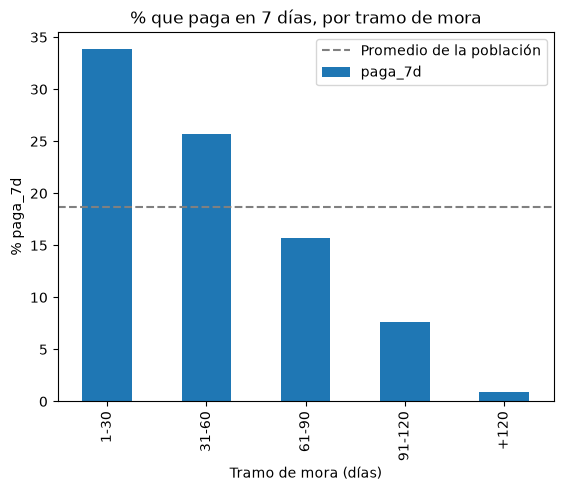

In [17]:
orden = ["1-30", "31-60", "61-90", "91-120", "+120"]
tasa_pago = obt.groupby("rango_mora")["paga_7d"].mean().reindex(orden) * 100
filas = obt["rango_mora"].value_counts().reindex(orden)
print(pd.DataFrame({"filas": filas, "% paga_7d": tasa_pago.round(1)}))

tasa_pago.plot(kind="bar")
plt.axhline(obt["paga_7d"].mean() * 100, color="gray", linestyle="--", label="Promedio de la población")
plt.title("% que paga en 7 días, por tramo de mora")
plt.xlabel("Tramo de mora (días)")
plt.ylabel("% paga_7d")
plt.legend()
plt.savefig("../docs/figuras/eda_pago_por_tramo.png", bbox_inches="tight")
plt.show()

**Hallazgo: la probabilidad de pago cae de forma monótona con la mora, y el tramo +120 casi no paga.**
- **Evidencia:** el % que paga en 7 días baja de 33.8% (1-30 días) a 25.7% (31-60), 15.7% (61-90), 7.7% (91-120) y 0.9% (+120). El tramo +120 concentra 28,115 filas (39% de la población).
- **Consecuencia en el modelo:**
  - `dias_mora` (o el tramo de mora) es la feature principal.
  - Como el 39% de la población casi nunca paga, un modelo puede verse bien solo por ubicar a los +120 al final de la lista. Por eso la evaluación de negocio se muestra también **dentro de los tramos 31-60 y 61-90**, que son las bases que el jefe de cobranzas trabaja cuando suben PAR 30 y PAR 60.
  - **Línea base de negocio:** el jefe de cobranzas define qué base trabajar (tramos, compromisos incumplidos, fin de mes) y el modelo ordena dentro de esa base. La línea base representa el orden actual dentro de la base con la regla **"mayor capital insoluto primero"**, que es lo que mueve los indicadores PAR.
  - Para el efecto incremental: en +120, la gestión probablemente cambia poco el resultado.

## 13. Resumen de hallazgos

| Hallazgo | Evidencia | Consecuencia en el modelo |
|---|---|---|
| Target desbalanceado | 18.67% paga en 7 días en la población en mora (1 positivo por cada 4 negativos) | Métrica técnica PR-AUC (no accuracy), `class_weight="balanced"` y umbral elegido por costo |
| La probabilidad de pago cae con la mora | 33.8% en 1-30 días vs. 0.9% en +120; el tramo +120 es el 39% de la población | `dias_mora` como feature principal; evaluación de negocio también dentro de los tramos 31-60 y 61-90; línea base de negocio "mayor capital insoluto primero" |
| Pagos de la OBT con fuga del objetivo | `num_pagos_dia` tiene la correlación más alta (0.34), pero se ubica por fecha valor, y muchos pagos se aplican días después | Se excluyen; no se usa una feature de pagos recientes |
| Colas largas con atípicos legítimos | Con IQR, 8% a 12% de atípicos en variables de mora y deuda; con Z-score, menos del 2% | No se eliminan; log(1 + x) y escalado para modelos lineales y red neuronal |
| Variables redundantes | Bloque de mora (0.84–0.96) y bloque de gestión (0.68–0.84) | Regularización L1/L2 en el modelo lineal; una sola variable de tratamiento (gestionado) |
| Plazo terminado | 9,496 filas sin próxima cuota: el 100% tiene todas sus cuotas pendientes vencidas (NON ACCRUAL, CASTIGADA, VENCIDO) | Feature derivada `plazo_terminado` |
| La gestión se concentra en mora | 0.1296 gestiones por día en mora vs. 0.0039 al día | Población del modelo: solo créditos en mora |